# Part 1 – Dataset Preparation and LSTM Model

## Hate Speech and Offensive Language Classification

**Objective:** Develop a three-class text classification model using a Long Short-Term Memory (LSTM) neural network implemented in PyTorch.

**Dataset:** Kaggle – Hate Speech and Offensive Language Dataset

**Classification Categories:**
- 0 – Hate Speech
- 1 – Offensive Language
- 2 – Neither

**Project Workflow:**
1. Dataset collection and exploration
2. Data cleaning and preprocessing
3. Stratified train/validation/test splitting
4. Text tokenization and sequence padding
5. LSTM model development
6. Model training and early stopping
7. Model checkpoint saving
8. Inference and prediction testing


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
# Install required libraries

!pip install -q pandas numpy scikit-learn matplotlib seaborn torch tqdm

In [3]:
# Import required libraries

import os
import re
import html
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch version: 2.14.1+cu130
GPU available: True


In [4]:
!pip install -q kaggle

In [5]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [6]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (24783, 6)

First 5 records:


,count,hate_speech_count,offensive_language_count,neither_count,class,tweet
0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...



Column names:
['count', 'hate_speech_count', 'offensive_language_count', 'neither_count', 'class', 'tweet']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   count                     24783 non-null  int64 
 1   hate_speech_count         24783 non-null  int64 
 2   offensive_language_count  24783 non-null  int64 
 3   neither_count             24783 non-null  int64 
 4   class                     24783 non-null  int64 
 5   tweet                     24783 non-null  object
dtypes: int64(5), object(1)
memory usage: 1.1+ MB


In [7]:
print("Label distribution:")
print(df['class'].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Label distribution:
class
0     1430
1    19190
2     4163
Name: count, dtype: int64

Missing values:
count                       0
hate_speech_count           0
offensive_language_count    0
neither_count               0
class                       0
tweet                       0
dtype: int64

Duplicate records:
0


## 2. Dataset Exploration

In this section, we explore the Hate Speech and Offensive Language dataset to understand its structure, classification categories, and distribution of records.

The dataset contains three target classes:
- Class 0: Hate Speech
- Class 1: Offensive Language
- Class 2: Neither

Understanding the distribution of these classes will help identify potential class imbalance before model development.

In [8]:
# Define classification labels

label_mapping = {
    0: "Hate Speech",
    1: "Offensive Language",
    2: "Neither"
}

# Count records in each class
class_counts = df['class'].value_counts().sort_index()

# Display counts and percentages
class_summary = pd.DataFrame({
    'Class': class_counts.index,
    'Category': class_counts.index.map(label_mapping),
    'Count': class_counts.values,
    'Percentage': (class_counts.values / len(df)) * 100
})

class_summary['Percentage'] = class_summary['Percentage'].round(2)

display(class_summary)

,Class,Category,Count,Percentage
0,0,Hate Speech,1430,5.77
1,1,Offensive Language,19190,77.43
2,2,Neither,4163,16.80


Visualize class distribution

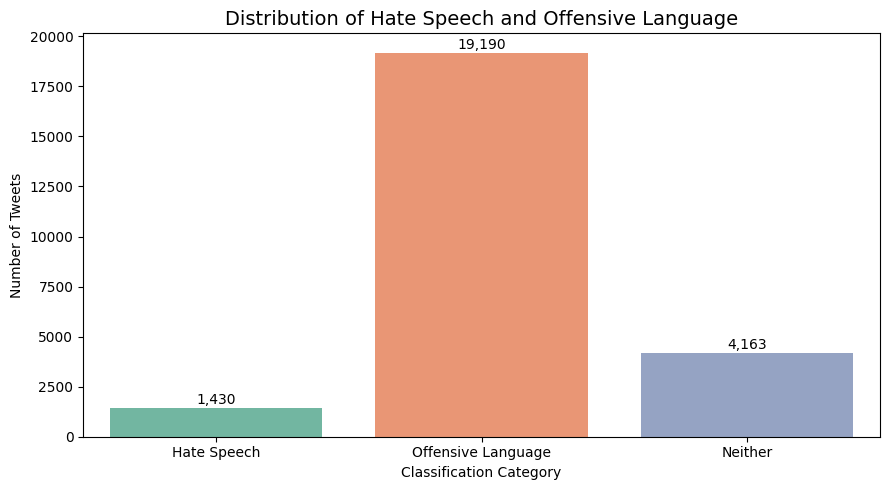

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=class_summary,
    x='Category',
    y='Count',
    hue='Category',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Hate Speech and Offensive Language',
          fontsize=14)
plt.xlabel('Classification Category')
plt.ylabel('Number of Tweets')

for i, value in enumerate(class_summary['Count']):
    plt.text(i, value + 200, f'{value:,}', ha='center')

plt.tight_layout()
plt.show()

Check missing values and duplicates

In [10]:
print("MISSING VALUE ANALYSIS")
print(df.isnull().sum())

print("\nDUPLICATE ANALYSIS")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate tweets:", df['tweet'].duplicated().sum())

print("\nUNIQUE CLASS LABELS")
print(sorted(df['class'].unique()))

MISSING VALUE ANALYSIS
count                       0
hate_speech_count           0
offensive_language_count    0
neither_count               0
class                       0
tweet                       0
dtype: int64

DUPLICATE ANALYSIS
Duplicate rows: 0
Duplicate tweets: 0

UNIQUE CLASS LABELS
[np.int64(0), np.int64(1), np.int64(2)]


**Validate annotation counts**

The dataset includes the number of annotators who classified each tweet. Let's check whether those counts add up correctly.

In [11]:
vote_sum = (
    df['hate_speech_count']
    + df['offensive_language_count']
    + df['neither_count']
)

print("Total records:", len(df))

print("Records with consistent annotation counts:",
      (vote_sum == df['count']).sum())

print("Records with inconsistent annotation counts:",
      (vote_sum != df['count']).sum())

Total records: 24783
Records with consistent annotation counts: 24783
Records with inconsistent annotation counts: 0


## 3. Data Cleaning and Preprocessing

The dataset was inspected for missing values, duplicate records, and invalid classification labels. No missing values or exact duplicate records were identified.

In this section, we will:
1. Retain only the tweet text and target label.
2. Validate the three classification labels.
3. Normalize tweet text.
4. Handle empty text records.
5. Identify duplicates created through text normalization.
6. Remove ambiguous duplicate records with conflicting labels.

The original annotation columns will not be used as model input features.

**Preparing the dataset**


In [12]:
# Use the uploaded file name from the upload cell

uploaded_filename = next(iter(uploaded.keys()))

df = pd.read_csv(uploaded_filename)

print("Loaded file:", uploaded_filename)
print("Dataset shape:", df.shape)

Loaded file: train.csv
Dataset shape: (24783, 6)


Select relevant columns and validate labels


In [13]:
# Retain only the text and target columns

df_clean = df[['tweet', 'class']].copy()

# Rename columns for consistency
df_clean.rename(
    columns={
        'tweet': 'text',
        'class': 'label'
    },
    inplace=True
)

# Validate labels
valid_labels = {0, 1, 2}

df_clean = df_clean[
    df_clean['label'].isin(valid_labels)
].copy()

# Remove missing and empty text
df_clean.dropna(subset=['text', 'label'], inplace=True)

df_clean['text'] = df_clean['text'].astype(str)

df_clean = df_clean[
    df_clean['text'].str.strip().ne('')
].copy()

df_clean.reset_index(drop=True, inplace=True)

print("Dataset shape after initial cleaning:", df_clean.shape)

print("\nLabel distribution:")
print(df_clean['label'].value_counts().sort_index())

Dataset shape after initial cleaning: (24783, 2)

Label distribution:
label
0     1430
1    19190
2     4163
Name: count, dtype: int64


**Text normalization**

We'll normalize text without aggressively removing meaningful information.

In [14]:
import re
import html

def clean_text(text):

    # Convert HTML entities
    text = html.unescape(str(text))

    # Convert text to lowercase
    text = text.lower()

    # Replace URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' <url> ',
        text
    )

    # Replace usernames
    text = re.sub(
        r'@\w+',
        ' <user> ',
        text
    )

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df_clean['text'] = df_clean['text'].apply(clean_text)

print("Text normalization completed!")

display(df_clean.head(10))

Text normalization completed!


,text,label
0,!!! rt <user> : as a woman you shouldn't compl...,2
1,!!!!! rt <user> : boy dats cold...tyga dwn bad...,1
2,!!!!!!! rt <user> dawg!!!! rt <user> : you eve...,1
3,!!!!!!!!! rt <user> : <user> she look like a t...,1
4,!!!!!!!!!!!!! rt <user> : the shit you hear ab...,1
5,"!!!!!!!!!!!!!!!!!!"" <user> : the shit just blo...",1
6,"!!!!!!"" <user> : i can not just sit up and hat...",1
7,!!!!“ <user> : cause i'm tired of you big bitc...,1
8,""" & you might not get ya bitch back & thats th...",1
9,""" <user> :hobbies include: fighting mariam"" bitch",1


**Remove normalized duplicates**

Although your original dataset has zero exact duplicate tweets, normalization can sometimes cause different raw tweets to become identical.

We'll also handle conflicting labels carefully.

In [15]:
# Identify texts with conflicting labels

label_counts = df_clean.groupby('text')['label'].nunique()

conflicting_texts = label_counts[
    label_counts > 1
].index

print("Conflicting normalized texts:", len(conflicting_texts))

# Remove all conflicting text groups
df_clean = df_clean[
    ~df_clean['text'].isin(conflicting_texts)
].copy()

# Remove remaining duplicate texts
before_deduplication = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=['text'],
    keep='first'
).reset_index(drop=True)

removed_duplicates = before_deduplication - len(df_clean)

print("Duplicate records removed:", removed_duplicates)
print("Final cleaned dataset shape:", df_clean.shape)


Conflicting normalized texts: 12
Duplicate records removed: 188
Final cleaned dataset shape: (24544, 2)


**Final Validation**

In [16]:
print("FINAL DATASET VALIDATION")

print("\nDataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate texts:")
print(df_clean['text'].duplicated().sum())

print("\nUnique labels:")
print(sorted(df_clean['label'].unique()))

print("\nFinal class distribution:")
print(df_clean['label'].value_counts().sort_index())

assert df_clean['text'].notna().all()
assert df_clean['text'].str.strip().ne('').all()
assert df_clean['label'].isin([0, 1, 2]).all()
assert not df_clean['text'].duplicated().any()

print("\nAll validation checks passed!")

FINAL DATASET VALIDATION

Dataset shape: (24544, 2)

Missing values:
text     0
label    0
dtype: int64

Duplicate texts:
0

Unique labels:
[np.int64(0), np.int64(1), np.int64(2)]

Final class distribution:
label
0     1413
1    19020
2     4111
Name: count, dtype: int64

All validation checks passed!


Save the cleaned dataset

In [17]:
import os

os.makedirs('/content/processed', exist_ok=True)

df_clean.to_csv(
    '/content/processed/cleaned_hate_speech.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 4. Stratified Train / Validation / Test Split (70 / 15 / 15)

The split is done **once**, with a fixed seed, and saved to disk. The same three files are used by the LSTM here and by the DistilBERT implementation.


In [18]:
import os, json, hashlib
from sklearn.model_selection import train_test_split

SEED = 42
SPLIT_DIR = '/content/processed/splits'
os.makedirs(SPLIT_DIR, exist_ok=True)

# Work from a fixed, deterministic row order
df_split = df_clean[['text', 'label']].reset_index(drop=True)

train_df, temp_df = train_test_split(
    df_split,
    test_size=0.30,
    stratify=df_split['label'],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"Train: {len(train_df):,}  Validation: {len(val_df):,}  Test: {len(test_df):,}  Total: {len(train_df)+len(val_df)+len(test_df):,}")


Train: 17,180  Validation: 3,682  Test: 3,682  Total: 24,544


In [19]:
# Split verification

label_mapping = {0: "Hate Speech", 1: "Offensive Language", 2: "Neither"}

summary = pd.DataFrame({
    'Full':  df_split['label'].value_counts().sort_index(),
    'Train': train_df['label'].value_counts().sort_index(),
    'Val':   val_df['label'].value_counts().sort_index(),
    'Test':  test_df['label'].value_counts().sort_index(),
})
summary.index = summary.index.map(label_mapping)
display(summary)

pct = (summary / summary.sum() * 100).round(2)
print("\nClass proportions (%):")
display(pct)

# 1. No missing rows, no extra rows
assert len(train_df) + len(val_df) + len(test_df) == len(df_split)

# 2. No text appears in more than one split (no leakage)
train_set, val_set, test_set = set(train_df['text']), set(val_df['text']), set(test_df['text'])
assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

# 3. Together the splits cover exactly the cleaned dataset
assert (train_set | val_set | test_set) == set(df_split['text'])

# 4. Class proportions preserved within 0.2 percentage points
full_pct = df_split['label'].value_counts(normalize=True).sort_index() * 100
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_pct = d['label'].value_counts(normalize=True).sort_index() * 100
    assert (split_pct - full_pct).abs().max() < 0.2, name

print("\nAll split checks passed: no overlap, full coverage, stratification preserved.")

,Full,Train,Val,Test
label,,,,
Hate Speech,1413,989,212,212
Offensive Language,19020,13313,2853,2854
Neither,4111,2878,617,616



Class proportions (%):


,Full,Train,Val,Test
label,,,,
Hate Speech,5.76,5.76,5.76,5.76
Offensive Language,77.49,77.49,77.49,77.51
Neither,16.75,16.75,16.76,16.73



All split checks passed: no overlap, full coverage, stratification preserved.


In [20]:
# Save the exact splits (shared with the DistilBERT notebook)

train_df.to_csv(f'{SPLIT_DIR}/train.csv', index=False)
val_df.to_csv(f'{SPLIT_DIR}/val.csv', index=False)
test_df.to_csv(f'{SPLIT_DIR}/test.csv', index=False)

def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()[:16]

metadata = {
    'seed': SEED,
    'ratios': {'train': 0.70, 'val': 0.15, 'test': 0.15},
    'method': 'train_test_split stratified on label: 70% train, then 50/50 of remaining 30% into val/test',
    'label_mapping': {'0': 'Hate Speech', '1': 'Offensive Language', '2': 'Neither'},
    'columns': ['text', 'label'],
    'sizes': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'class_counts': {
        name: {str(k): int(v) for k, v in d['label'].value_counts().sort_index().items()}
        for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]
    },
    'sha256_prefix': {n: file_hash(f'{SPLIT_DIR}/{n}.csv') for n in ['train', 'val', 'test']},
}

with open(f'{SPLIT_DIR}/split_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# Reload and confirm the saved files match what is in memory
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    reloaded = pd.read_csv(f'{SPLIT_DIR}/{name}.csv', keep_default_na=False)
    assert reloaded['text'].tolist() == d['text'].tolist(), name
    assert reloaded['label'].tolist() == d['label'].tolist(), name

print("Splits saved and verified:")
print(json.dumps(metadata['sizes'], indent=2))
print(os.listdir(SPLIT_DIR))

Splits saved and verified:
{
  "train": 17180,
  "val": 3682,
  "test": 3682
}
['split_metadata.json', 'test.csv', 'train.csv', 'val.csv']


In [21]:
# Download a copy for your teammate (Colab storage is temporary)

import shutil
from google.colab import files

shutil.make_archive('/content/hate_speech_splits', 'zip', SPLIT_DIR)
files.download('/content/hate_speech_splits.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Tokenization, Vocabulary and Sequence Padding

Rules that keep the evaluation honest:
- The **vocabulary is built from the training split only**. Validation and test words not seen in training map to `<unk>`.
- The tokenizer keeps the `<user>` / `<url>` placeholders as single tokens and keeps `!` and `?`, which carry tone in tweets.
- Sequences are padded at the end, and the true lengths are stored so the LSTM can ignore the padding.

In [22]:
import re
from collections import Counter

TOKEN_PATTERN = re.compile(r"<user>|<url>|[a-z0-9]+(?:'[a-z]+)?|[!?]")

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

# Quick look at the tokenizer
for t in train_df['text'].head(5):
    print(t)
    print(tokenize(t))
    print()

<user> is little bitch an emotion? cuz i'm feeling it..
['<user>', 'is', 'little', 'bitch', 'an', 'emotion', '?', 'cuz', "i'm", 'feeling', 'it']

okay! rt <user> : right— bitch!!! rt <user> : you mad cause you opened your mouth? #greysanatomy
['okay', '!', 'rt', '<user>', 'right', 'bitch', '!', '!', '!', 'rt', '<user>', 'you', 'mad', 'cause', 'you', 'opened', 'your', 'mouth', '?', 'greysanatomy']

rt <user> : when all yo hoes hit you up at da same time.. <url>
['rt', '<user>', 'when', 'all', 'yo', 'hoes', 'hit', 'you', 'up', 'at', 'da', 'same', 'time', '<url>']

<user> i love racism! "blame whitey" for everything! now that you mention it! i bet the white man put the desert tortoise on #bundyranch
['<user>', 'i', 'love', 'racism', '!', 'blame', 'whitey', 'for', 'everything', '!', 'now', 'that', 'you', 'mention', 'it', '!', 'i', 'bet', 'the', 'white', 'man', 'put', 'the', 'desert', 'tortoise', 'on', 'bundyranch']

rt <user> : i hate when bitches say "that ain't cute" lol did i say i was 

count    17180.0
mean        14.2
std          6.9
min          1.0
25%          9.0
50%         13.0
75%         20.0
max         37.0
Name: tokens, dtype: float64
90th percentile length: 24
95th percentile length: 26
99th percentile length: 29


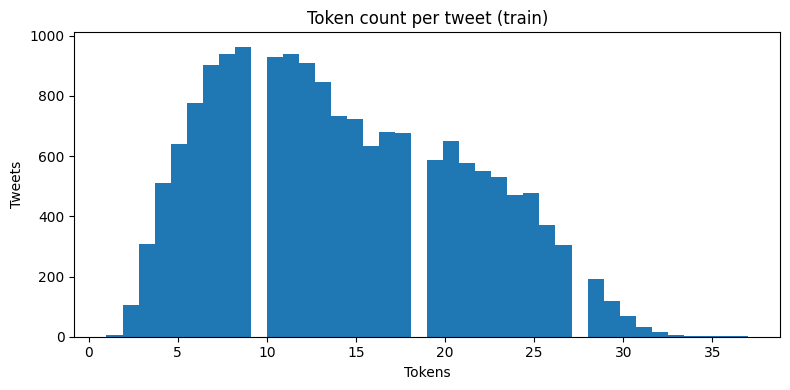

In [23]:
# Token length statistics (training split only)

train_df['tokens'] = train_df['text'].apply(tokenize)
val_df['tokens']   = val_df['text'].apply(tokenize)
test_df['tokens']  = test_df['text'].apply(tokenize)

lengths = train_df['tokens'].apply(len)
print(lengths.describe().round(1))
for q in [90, 95, 99]:
    print(f"{q}th percentile length: {int(np.percentile(lengths, q))}")

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=40)
plt.title('Token count per tweet (train)')
plt.xlabel('Tokens'); plt.ylabel('Tweets')
plt.tight_layout(); plt.show()

In [24]:
# Build the vocabulary from the TRAINING split only

PAD, UNK = '<pad>', '<unk>'
MIN_FREQ  = 2
MAX_VOCAB = 20000

counter = Counter(tok for toks in train_df['tokens'] for tok in toks)
print("Unique training tokens:", len(counter))

most_common = [w for w, c in counter.most_common() if c >= MIN_FREQ][:MAX_VOCAB - 2]

itos = [PAD, UNK] + most_common
stoi = {w: i for i, w in enumerate(itos)}

PAD_IDX, UNK_IDX = stoi[PAD], stoi[UNK]
VOCAB_SIZE = len(itos)

print("Vocabulary size (incl. <pad>, <unk>):", VOCAB_SIZE)
print("Tokens dropped (freq <", MIN_FREQ, "):", len(counter) - len(most_common))

def coverage(df):
    total = sum(len(t) for t in df['tokens'])
    known = sum(1 for toks in df['tokens'] for tok in toks if tok in stoi)
    return known / total * 100

print(f"\nToken coverage -> train: {coverage(train_df):.2f}%  val: {coverage(val_df):.2f}%  test: {coverage(test_df):.2f}%")

Unique training tokens: 17196
Vocabulary size (incl. <pad>, <unk>): 7861
Tokens dropped (freq < 2 ): 9337

Token coverage -> train: 96.18%  val: 94.15%  test: 94.17%


In [25]:
# Encode and pad

p95 = int(np.percentile(lengths, 95))
MAX_LEN = int(np.ceil(p95 / 5) * 5)     # round up to a multiple of 5
print("MAX_LEN:", MAX_LEN)

def encode_and_pad(tokens, max_len=MAX_LEN):
    ids = [stoi.get(tok, UNK_IDX) for tok in tokens][:max_len]
    length = max(len(ids), 1)            # avoid zero-length sequences
    ids = ids + [PAD_IDX] * (max_len - len(ids))
    return ids, length

def build_tensors(df):
    encoded = [encode_and_pad(toks) for toks in df['tokens']]
    X = torch.tensor([e[0] for e in encoded], dtype=torch.long)
    L = torch.tensor([e[1] for e in encoded], dtype=torch.long)
    y = torch.tensor(df['label'].values, dtype=torch.long)
    return X, L, y

X_train, L_train, y_train = build_tensors(train_df)
X_val,   L_val,   y_val   = build_tensors(val_df)
X_test,  L_test,  y_test  = build_tensors(test_df)

print("X_train:", tuple(X_train.shape), " X_val:", tuple(X_val.shape), " X_test:", tuple(X_test.shape))

truncated = (train_df['tokens'].apply(len) > MAX_LEN).mean() * 100
print(f"Tweets truncated in train: {truncated:.2f}%")

# Sanity checks
assert X_train.shape == (len(train_df), MAX_LEN)
assert X_train.max().item() < VOCAB_SIZE and X_train.min().item() >= 0
assert (L_train >= 1).all() and (L_train <= MAX_LEN).all()
assert set(y_train.unique().tolist()) == {0, 1, 2}

print("\nExample")
print("Text   :", train_df['text'].iloc[0])
print("Tokens :", train_df['tokens'].iloc[0])
print("IDs    :", X_train[0].tolist())
print("Length :", L_train[0].item())
print("\nAll encoding checks passed!")

MAX_LEN: 30
X_train: (17180, 30)  X_val: (3682, 30)  X_test: (3682, 30)
Tweets truncated in train: 0.37%

Example
Text   : <user> is little bitch an emotion? cuz i'm feeling it..
Tokens : ['<user>', 'is', 'little', 'bitch', 'an', 'emotion', '?', 'cuz', "i'm", 'feeling', 'it']
IDs    : [2, 17, 144, 4, 103, 5395, 20, 221, 31, 1197, 28, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Length : 11

All encoding checks passed!


In [26]:
# Datasets and DataLoaders

from torch.utils.data import TensorDataset

BATCH_SIZE = 64
g = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(TensorDataset(X_train, L_train, y_train), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(TensorDataset(X_val,   L_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test,  L_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

xb, lb, yb = next(iter(train_loader))
print("Batch shapes -> X:", tuple(xb.shape), " lengths:", tuple(lb.shape), " y:", tuple(yb.shape))

Batch shapes -> X: (64, 30)  lengths: (64,)  y: (64,)


In [27]:
# Save vocabulary and preprocessing config (needed later for inference)

ART_DIR = '/content/processed/lstm_artifacts'
os.makedirs(ART_DIR, exist_ok=True)

with open(f'{ART_DIR}/vocab.json', 'w') as f:
    json.dump({'itos': itos}, f)

config = {
    'token_pattern': TOKEN_PATTERN.pattern,
    'min_freq': MIN_FREQ,
    'max_vocab': MAX_VOCAB,
    'vocab_size': VOCAB_SIZE,
    'max_len': MAX_LEN,
    'pad_idx': PAD_IDX,
    'unk_idx': UNK_IDX,
    'seed': SEED,
    'batch_size': BATCH_SIZE,
}
with open(f'{ART_DIR}/preprocess_config.json', 'w') as f:
    json.dump(config, f, indent=2)

print(json.dumps(config, indent=2))
print(os.listdir(ART_DIR))

{
  "token_pattern": "<user>|<url>|[a-z0-9]+(?:'[a-z]+)?|[!?]",
  "min_freq": 2,
  "max_vocab": 20000,
  "vocab_size": 7861,
  "max_len": 30,
  "pad_idx": 0,
  "unk_idx": 1,
  "seed": 42,
  "batch_size": 64
}
['preprocess_config.json', 'vocab.json']


## 6. LSTM Architecture

**Model:** Embedding → 2-layer bidirectional LSTM → dropout → small classifier head (3 classes).

- Padding is handled with `pack_padded_sequence`, so the LSTM never reads `<pad>` positions.
- The sentence representation is the final forward and backward hidden states of the top LSTM layer, concatenated.
- Dropout is applied on the embeddings, between LSTM layers, and before the classifier to limit overfitting.

**Class imbalance:** Hate Speech is only about 5.8% of the data, and always predicting "Offensive" already scores about 77% accuracy. Training therefore uses a class-weighted loss, and model selection (next section) will use **macro-F1** on the validation set rather than accuracy.

In [28]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128,
                 num_layers=2, num_classes=3, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes),
        )

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (h_n, _) = self.lstm(packed)
        # h_n: (num_layers * 2, batch, hidden) -> last layer forward = [-2], backward = [-1]
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)
        return self.classifier(self.dropout(h))

Device: cuda


In [29]:
# Instantiate the model

EMBED_DIM  = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
DROPOUT    = 0.3

model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    num_classes=3,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {n_params:,}")

# Sanity check: one batch through the untrained model
xb, lb, yb = next(iter(train_loader))
model.eval()
with torch.no_grad():
    logits = model(xb.to(device), lb.to(device))

print("\nInput batch :", tuple(xb.shape))
print("Output shape:", tuple(logits.shape), "(expected (64, 3))")
assert logits.shape == (xb.shape[0], 3)
assert torch.isfinite(logits).all()
print("Forward pass OK")

LSTMClassifier(
  (embedding): Embedding(7861, 128, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

Trainable parameters: 1,682,307

Input batch : (64, 30)
Output shape: (64, 3) (expected (64, 3))
Forward pass OK


In [30]:
# Class-weighted loss and optimizer

class_counts = np.bincount(train_df['label'].values, minlength=3)
class_weights = len(train_df) / (3.0 * class_counts)          # inverse frequency
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Training class counts:", class_counts.tolist())
for i, w in enumerate(class_weights):
    print(f"  weight[{i}] {label_mapping[i]:<20} {w:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights_t)

LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Untrained loss should be near ln(3) = 1.099 (weighted, so roughly)
model.eval()
with torch.no_grad():
    init_loss = criterion(model(xb.to(device), lb.to(device)), yb.to(device)).item()
print(f"\nInitial loss on one batch: {init_loss:.3f}")

Training class counts: [989, 13313, 2878]
  weight[0] Hate Speech          5.790
  weight[1] Offensive Language   0.430
  weight[2] Neither              1.990

Initial loss on one batch: 1.108


## 7. Training with Early Stopping

- **Selection metric:** validation **macro-F1** (accuracy would reward predicting "Offensive" for everything).
- **Early stopping:** training stops when validation macro-F1 hasn't improved for `PATIENCE` epochs. The best epoch's weights are saved as the checkpoint.
- **Learning rate:** halved when validation macro-F1 stalls for 2 epochs.
- **Gradient clipping** at 1.0 keeps LSTM training stable.
- The **test set is not touched here.** It is evaluated exactly once, in the next section, using the saved best checkpoint.

In [31]:
from sklearn.metrics import f1_score

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.no_grad():
        for xb, lb, yb in loader:
            xb, lb, yb = xb.to(device), lb.to(device), yb.to(device)
            logits = model(xb, lb)
            total_loss += criterion(logits, yb).item() * yb.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_labels.extend(yb.cpu().tolist())
    avg_loss = total_loss / len(all_labels)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    acc = float(np.mean(np.array(all_preds) == np.array(all_labels)))
    return avg_loss, macro_f1, acc, all_preds, all_labels


def train_one_epoch(model, loader, criterion, optimizer, clip=1.0):
    model.train()
    total_loss, n = 0.0, 0
    for xb, lb, yb in loader:
        xb, lb, yb = xb.to(device), lb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb, lb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        total_loss += loss.item() * yb.size(0)
        n += yb.size(0)
    return total_loss / n

print("Training helpers defined.")

Training helpers defined.


In [32]:
# Training loop

MAX_EPOCHS = 30
PATIENCE   = 5
CHECKPOINT_PATH = f'{ART_DIR}/best_lstm.pt'

# Fresh model + optimizer so this cell is safe to re-run
set_seed()
model_args = dict(vocab_size=VOCAB_SIZE, embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
                  num_layers=NUM_LAYERS, num_classes=3, dropout=DROPOUT, pad_idx=PAD_IDX)
model = LSTMClassifier(**model_args).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

history = []
best_f1, best_epoch, epochs_without_improvement = -1.0, 0, 0

print(f"{'Epoch':>5} | {'Train loss':>10} | {'Val loss':>8} | {'Val acc':>7} | {'Val macro-F1':>12} | {'LR':>8}")
print("-" * 66)

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_f1, val_acc, _, _ = evaluate(model, val_loader, criterion)
    scheduler.step(val_f1)
    lr = optimizer.param_groups[0]['lr']

    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'val_acc': val_acc, 'val_macro_f1': val_f1, 'lr': lr})

    flag = ""
    if val_f1 > best_f1:
        best_f1, best_epoch, epochs_without_improvement = val_f1, epoch, 0
        torch.save({
            'model_state': model.state_dict(),
            'model_args': model_args,
            'epoch': epoch,
            'val_macro_f1': val_f1,
        }, CHECKPOINT_PATH)
        flag = "  <- best, saved"
    else:
        epochs_without_improvement += 1

    print(f"{epoch:>5} | {train_loss:>10.4f} | {val_loss:>8.4f} | {val_acc:>7.4f} | {val_f1:>12.4f} | {lr:>8.5f}{flag}")

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping: no improvement for {PATIENCE} epochs.")
        break

print(f"\nBest validation macro-F1: {best_f1:.4f} at epoch {best_epoch}")
print("Checkpoint:", CHECKPOINT_PATH)

Epoch | Train loss | Val loss | Val acc | Val macro-F1 |       LR
------------------------------------------------------------------
    1 |     0.8585 |   0.6609 |  0.8218 |       0.6634 |  0.00100  <- best, saved
    2 |     0.6249 |   0.5961 |  0.8474 |       0.6943 |  0.00100  <- best, saved
    3 |     0.5251 |   0.6331 |  0.8498 |       0.7029 |  0.00100  <- best, saved
    4 |     0.4417 |   0.6609 |  0.8387 |       0.6964 |  0.00100
    5 |     0.3790 |   0.6698 |  0.8237 |       0.6930 |  0.00100
    6 |     0.3330 |   0.8125 |  0.8569 |       0.7139 |  0.00100  <- best, saved
    7 |     0.2857 |   0.8257 |  0.8688 |       0.7205 |  0.00100  <- best, saved
    8 |     0.2542 |   0.9616 |  0.8593 |       0.7129 |  0.00100
    9 |     0.2201 |   1.1897 |  0.8599 |       0.7097 |  0.00100
   10 |     0.1999 |   1.2614 |  0.8748 |       0.7284 |  0.00100  <- best, saved
   11 |     0.1739 |   1.3216 |  0.8726 |       0.7144 |  0.00100
   12 |     0.1631 |   1.3488 |  0.8770 |    

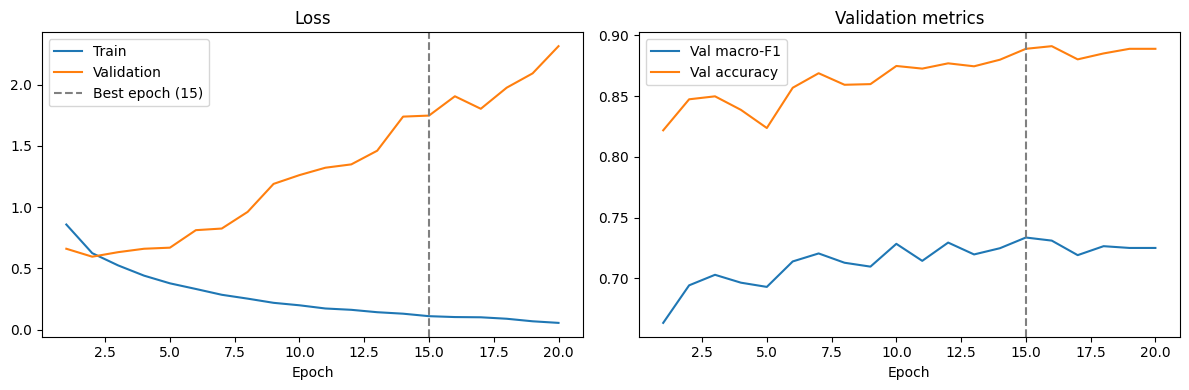

In [33]:
# Training curves

hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist['epoch'], hist['train_loss'], label='Train')
axes[0].plot(hist['epoch'], hist['val_loss'], label='Validation')
axes[0].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(hist['epoch'], hist['val_macro_f1'], label='Val macro-F1')
axes[1].plot(hist['epoch'], hist['val_acc'], label='Val accuracy')
axes[1].axvline(best_epoch, color='gray', linestyle='--')
axes[1].set_title('Validation metrics'); axes[1].set_xlabel('Epoch'); axes[1].legend()

plt.tight_layout()
plt.show()

hist.to_csv(f'{ART_DIR}/training_history.csv', index=False)

Best checkpoint (epoch 15) -> val loss 1.7467 | val acc 0.8889 | val macro-F1 0.7336

                    precision    recall  f1-score   support

       Hate Speech      0.383     0.425     0.403       212
Offensive Language      0.959     0.911     0.934      2853
           Neither      0.794     0.948     0.864       617

          accuracy                          0.889      3682
         macro avg      0.712     0.761     0.734      3682
      weighted avg      0.898     0.889     0.892      3682



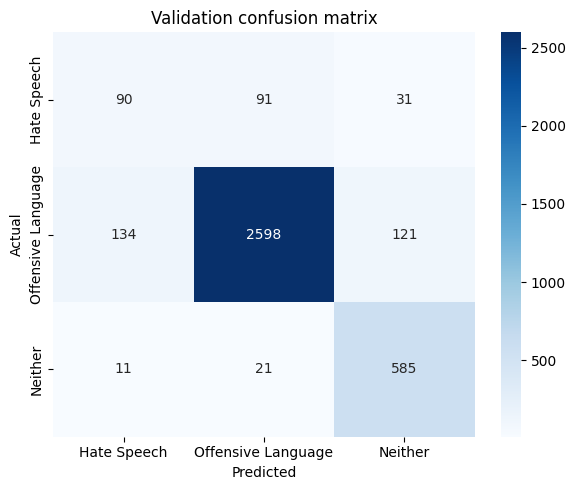

In [34]:
# Reload the best checkpoint and report on the VALIDATION set (test set stays untouched)

ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
best_model = LSTMClassifier(**ckpt['model_args']).to(device)
best_model.load_state_dict(ckpt['model_state'])

val_loss, val_f1, val_acc, val_preds, val_labels = evaluate(best_model, val_loader, criterion)
print(f"Best checkpoint (epoch {ckpt['epoch']}) -> val loss {val_loss:.4f} | val acc {val_acc:.4f} | val macro-F1 {val_f1:.4f}\n")

target_names = [label_mapping[i] for i in range(3)]
print(classification_report(val_labels, val_preds, target_names=target_names, digits=3))

cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Validation confusion matrix')
plt.tight_layout()
plt.show()

## 8. Final Test Evaluation, Saved Artifacts and Inference

- The **test set is evaluated once**, using the best checkpoint chosen on validation. Do not change the model or hyperparameters after looking at these numbers.
- Test predictions are saved with the true labels, so the DistilBERT results can be compared row by row on the identical test split.
- The inference function is rebuilt **only from the saved files** (`vocab.json`, `preprocess_config.json`, `best_lstm.pt`), which confirms those files are enough to use the model later.

Checkpoint from epoch 15 (val macro-F1 0.7336)

TEST  loss 1.7269 | accuracy 0.8772 | macro-F1 0.7194 | weighted-F1 0.8814

                    precision    recall  f1-score   support

       Hate Speech      0.360     0.420     0.388       212
Offensive Language      0.957     0.897     0.926      2854
           Neither      0.764     0.943     0.844       616

          accuracy                          0.877      3682
         macro avg      0.694     0.753     0.719      3682
      weighted avg      0.890     0.877     0.881      3682



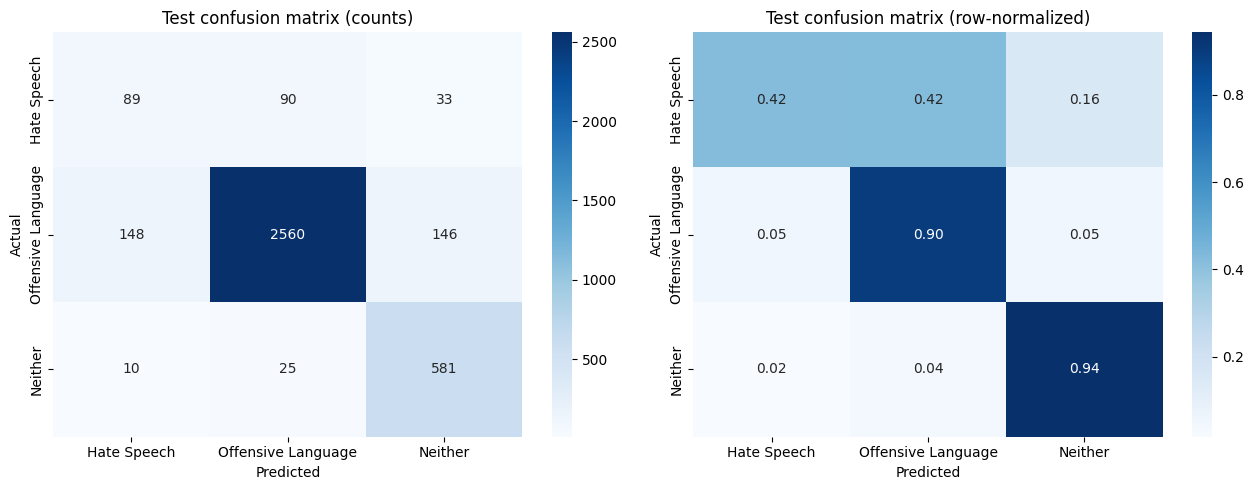

In [35]:
# One-time evaluation on the held-out TEST set

ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
final_model = LSTMClassifier(**ckpt['model_args']).to(device)
final_model.load_state_dict(ckpt['model_state'])

test_loss, test_f1, test_acc, test_preds, test_labels = evaluate(final_model, test_loader, criterion)
weighted_f1 = f1_score(test_labels, test_preds, average='weighted')

print(f"Checkpoint from epoch {ckpt['epoch']} (val macro-F1 {ckpt['val_macro_f1']:.4f})\n")
print(f"TEST  loss {test_loss:.4f} | accuracy {test_acc:.4f} | macro-F1 {test_f1:.4f} | weighted-F1 {weighted_f1:.4f}\n")

target_names = [label_mapping[i] for i in range(3)]
print(classification_report(test_labels, test_preds, target_names=target_names, digits=3))

cm = confusion_matrix(test_labels, test_preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title('Test confusion matrix (counts)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title('Test confusion matrix (row-normalized)')
for ax in axes:
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [36]:
# Save test predictions and metrics (for comparison with the DistilBERT model)

pred_df = test_df[['text', 'label']].copy()
pred_df['lstm_pred'] = test_preds
pred_df['correct'] = (pred_df['label'] == pred_df['lstm_pred'])
pred_df.to_csv(f'{ART_DIR}/lstm_test_predictions.csv', index=False)

results = {
    'model': 'BiLSTM (2 layers, 128 hidden)',
    'checkpoint_epoch': int(ckpt['epoch']),
    'val_macro_f1': float(ckpt['val_macro_f1']),
    'test': {
        'loss': float(test_loss),
        'accuracy': float(test_acc),
        'macro_f1': float(test_f1),
        'weighted_f1': float(weighted_f1),
        'per_class_f1': {
            label_mapping[i]: float(v)
            for i, v in enumerate(f1_score(test_labels, test_preds, average=None))
        },
    },
    'split_seed': SEED,
}
with open(f'{ART_DIR}/lstm_test_results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))

# A few misclassified Hate Speech tweets, for error analysis
print("\nSample Hate Speech tweets the model missed:")
missed = pred_df[(pred_df['label'] == 0) & (pred_df['lstm_pred'] != 0)]
print(f"({len(missed)} of {(pred_df['label'] == 0).sum()} missed)")
for _, r in missed.head(5).iterrows():
    print(f"  predicted {label_mapping[r['lstm_pred']]:<18} | {r['text'][:110]}")

{
  "model": "BiLSTM (2 layers, 128 hidden)",
  "checkpoint_epoch": 15,
  "val_macro_f1": 0.7336064390835827,
  "test": {
    "loss": 1.7268883168600229,
    "accuracy": 0.8772406300923411,
    "macro_f1": 0.7194342382259796,
    "weighted_f1": 0.8813934126563614,
    "per_class_f1": {
      "Hate Speech": 0.3877995642701525,
      "Offensive Language": 0.9260264062217399,
      "Neither": 0.8444767441860465
    }
  },
  "split_seed": 42
}

Sample Hate Speech tweets the model missed:
(123 of 212 missed)
  predicted Offensive Language | <user> shut your legs hoe
  predicted Offensive Language | what these bitches want from a nigga?, like on some dmx shit
  predicted Offensive Language | <user> lmao why ur dad raised u to be a bitch made nigga
  predicted Neither            | rt <user> : we muslims have no military honour whatsoever, we are sub human savages that slaughter unarmed men
  predicted Offensive Language | rt <user> : chava needs to stay in his lane and keep sending gyro to he

In [37]:
# Inference, rebuilt ONLY from the saved files

with open(f'{ART_DIR}/vocab.json') as f:
    saved_itos = json.load(f)['itos']
with open(f'{ART_DIR}/preprocess_config.json') as f:
    saved_cfg = json.load(f)

saved_stoi = {w: i for i, w in enumerate(saved_itos)}
saved_pattern = re.compile(saved_cfg['token_pattern'])

inf_ckpt = torch.load(f'{ART_DIR}/best_lstm.pt', map_location=device, weights_only=True)
inf_model = LSTMClassifier(**inf_ckpt['model_args']).to(device)
inf_model.load_state_dict(inf_ckpt['model_state'])
inf_model.eval()


def predict(texts):
    """Classify one string or a list of strings. Returns a list of dicts."""
    if isinstance(texts, str):
        texts = [texts]

    cleaned = [clean_text(t) for t in texts]
    ids_list, len_list = [], []
    for t in cleaned:
        toks = saved_pattern.findall(t)
        ids = [saved_stoi.get(tok, saved_cfg['unk_idx']) for tok in toks][:saved_cfg['max_len']]
        length = max(len(ids), 1)
        ids = ids + [saved_cfg['pad_idx']] * (saved_cfg['max_len'] - len(ids))
        ids_list.append(ids)
        len_list.append(length)

    x = torch.tensor(ids_list, dtype=torch.long).to(device)
    l = torch.tensor(len_list, dtype=torch.long).to(device)
    with torch.no_grad():
        probs = torch.softmax(inf_model(x, l), dim=1).cpu().numpy()

    out = []
    for text, p in zip(texts, probs):
        k = int(p.argmax())
        out.append({
            'text': text,
            'label': k,
            'label_name': label_mapping[k],
            'confidence': round(float(p[k]), 3),
            'probabilities': {label_mapping[i]: round(float(p[i]), 3) for i in range(3)},
        })
    return out


demo = [
    "Have a wonderful day everyone, thanks for all the support!",
    "shut up you stupid idiot, nobody asked you",
    "@someone check out this article http://example.com/news",
    "that movie was absolutely terrible",
]
for r in predict(demo):
    print(f"{r['label_name']:<18} ({r['confidence']:.2f})  <-  {r['text']}")

Neither            (1.00)  <-  Have a wonderful day everyone, thanks for all the support!
Hate Speech        (0.98)  <-  shut up you stupid idiot, nobody asked you
Neither            (0.93)  <-  @someone check out this article http://example.com/news
Neither            (0.88)  <-  that movie was absolutely terrible


In [38]:
# Consistency check: saved-file inference must reproduce the evaluation predictions

check = predict(test_df['text'].tolist())
check_preds = [r['label'] for r in check]

match = np.mean(np.array(check_preds) == np.array(test_preds))
print(f"Agreement between predict() and the evaluated model on the test set: {match * 100:.2f}%")
assert match > 0.995, "Inference pipeline does not reproduce evaluation predictions!"
print("Inference pipeline verified.")

# Final artifact list
print("\nSaved artifacts:")
for name in sorted(os.listdir(ART_DIR)):
    size_kb = os.path.getsize(f'{ART_DIR}/{name}') / 1024
    print(f"  {name:<32} {size_kb:>8.1f} KB")

Agreement between predict() and the evaluated model on the test set: 100.00%
Inference pipeline verified.

Saved artifacts:
  best_lstm.pt                       6576.2 KB
  lstm_test_predictions.csv           314.7 KB
  lstm_test_results.json                0.4 KB
  preprocess_config.json                0.2 KB
  training_history.csv                  1.7 KB
  vocab.json                           75.0 KB


In [39]:
# Download all LSTM artifacts as one zip

import shutil
from google.colab import files

shutil.make_archive('/content/lstm_artifacts', 'zip', ART_DIR)
files.download('/content/lstm_artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>